# Hotel booking cancellation: a retrospective classification study

**Ahmad Sajjad Siddiqui** | M505, Introduction to AI and Machine Learning | Gisma University of Applied Sciences

This portfolio copy preserves the submitted experiment's modelling choices. It clarifies the interpretation and evaluation limits identified during publication review. The original final submission is retained unchanged.

## 1. Question

Can a historical booking table distinguish cancellations from completed bookings? This is binary classification, with `is_canceled` as the target. The potential business application is prioritising manual booking reviews. Actual time savings, revenue benefit and safe overbooking decisions have not been measured.

The data is a historical snapshot. The study does not establish that all retained features were available when a proposed intervention would have occurred.

## 2. Data

Antonio, de Almeida and Nunes (2019) describe bookings from a resort and a city hotel in Portugal, with arrivals from July 2015 through August 2017. The supplied combined CSV contains 119,390 rows and 32 columns. It matches the TidyTuesday mirror byte for byte; the source and CC BY 4.0 attribution are recorded in `data/README.md`.

Use the bundled, hash-verified snapshot to reproduce this experiment. The original code's remote fallback remains for provenance, but the supported runner verifies the local input before execution.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = os.environ.get("HOTEL_MAX_WORKERS", "2")  # bound parallel workers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit, StratifiedKFold, cross_val_score, validation_curve, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score, log_loss

RANDOM_STATE = 42
CSV = "hotel_bookings.csv"
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(CSV if os.path.exists(CSV) else URL)
df.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


### 2.1 Arrival-ordered split

The code sorts by arrival date and reserves the last 20% of rows before exploration. Cleaning is then applied separately to the two partitions. The final training arrival and first test arrival are both 22 April 2017, so this is not a separation by complete calendar days. Publication review also found five exact cleaned row patterns in both partitions.

The original split is retained to reproduce the submitted experiment. Its scores are retrospective and do not establish record-independent or prospectively unseen testing. See `reports/METHODOLOGY_REVIEW.md`.

In [2]:
month = pd.to_datetime(df["arrival_date_month"], format="%B").dt.month
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"], month=month, day=df["arrival_date_day_of_month"]))
df = df.sort_values("arrival_date", kind="stable").reset_index(drop=True)
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
print("Train:", train_df.shape, "| Test:", test_df.shape, "| test arrivals from", test_df["arrival_date"].min().date())

Train: (95512, 33) | Test: (23878, 33) | test arrivals from 2017-04-22


## 3. Exploration of the development partition

In [3]:
train_df.info()
print("Duplicates:", train_df.duplicated().sum(), "| ADR outside 0-1000:", (~train_df["adr"].between(0, 1000)).sum(),
      "| zero guests:", (train_df[["adults", "children", "babies"]].sum(axis=1) == 0).sum())
train_df.describe().T.round(1)

<class 'pandas.core.frame.DataFrame'>
Index: 95512 entries, 0 to 95511
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           95512 non-null  object        
 1   is_canceled                     95512 non-null  int64         
 2   lead_time                       95512 non-null  int64         
 3   arrival_date_year               95512 non-null  int64         
 4   arrival_date_month              95512 non-null  object        
 5   arrival_date_week_number        95512 non-null  int64         
 6   arrival_date_day_of_month       95512 non-null  int64         
 7   stays_in_weekend_nights         95512 non-null  int64         
 8   stays_in_week_nights            95512 non-null  int64         
 9   adults                          95512 non-null  int64         
 10  children                        95508 non-null  float64       
 11  babies 

,count,mean,min,25%,50%,75%,max,std
is_canceled,95512.0,0.360876,0.0,0.0,0.0,1.0,1.0,0.480257
lead_time,95512.0,96.480536,0.0,15.0,60.0,145.0,737.0,104.619571
arrival_date_year,95512.0,2015.945693,2015.0,2016.0,2016.0,2016.0,2017.0,0.63509
arrival_date_week_number,95512.0,27.630392,1.0,14.0,29.0,41.0,53.0,14.934476
arrival_date_day_of_month,95512.0,15.637135,1.0,8.0,16.0,23.0,31.0,8.7059
stays_in_weekend_nights,95512.0,0.904075,0.0,0.0,1.0,2.0,19.0,1.000535
stays_in_week_nights,95512.0,2.454362,0.0,1.0,2.0,3.0,50.0,1.92105
adults,95512.0,1.839109,0.0,2.0,2.0,2.0,55.0,0.601713
children,95508.0,0.092725,0.0,0.0,0.0,0.0,10.0,0.37734
babies,95512.0,0.008219,0.0,0.0,0.0,0.0,10.0,0.100597


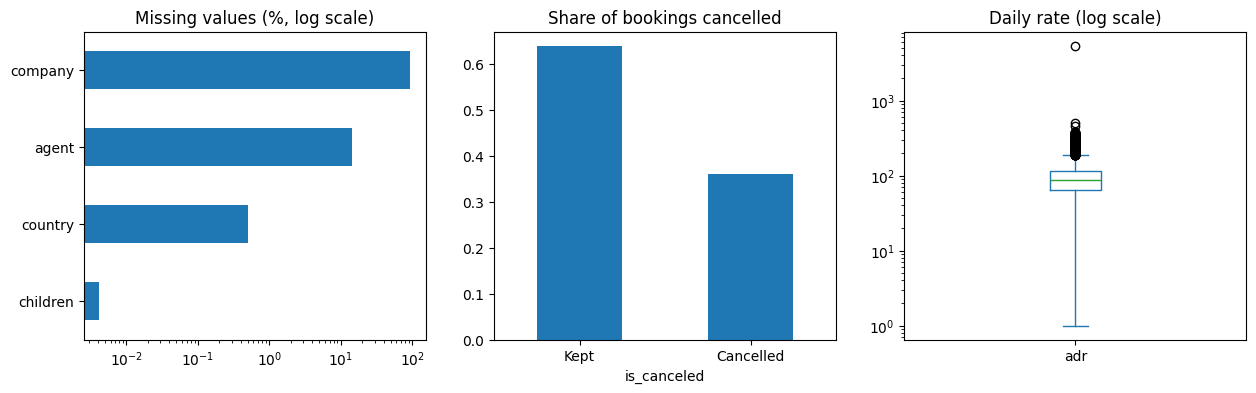

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
missing = train_df.isna().mean() * 100
missing[missing > 0].plot.barh(ax=ax[0], logx=True, title="Missing values (%, log scale)")
train_df["is_canceled"].value_counts(normalize=True).rename({0: "Kept", 1: "Cancelled"}).plot.bar(
    ax=ax[1], rot=0, title="Share of bookings cancelled")
train_df["adr"].clip(lower=1).plot.box(ax=ax[2], logy=True, title="Daily rate (log scale)")
plt.show()

**Reading the audit.**

- The source paper treats `NULL` agent/company values as not applicable. Pandas parses them as missing; the pipeline gives them a category and creates agency/company-presence indicators. In the raw development partition, about 14.44% of agent entries and 93.80% of company entries have this representation.
- Exact repeated rows are removed within each partition. Without booking identifiers, this can remove legitimate identical bookings, and it does not eliminate the five cross-partition repeated patterns.
- ADR outside 0–1000 and records with no guests are excluded by fixed rules. These are analytical choices, not independently established data errors.
- Class balance changes after cleaning. ROC-AUC is used for candidate comparison; threshold-dependent precision, recall and F1 are also reported.
- Scaling can affect regularised models and solver convergence. The unscaled logistic baseline reaches its iteration cap in this run.

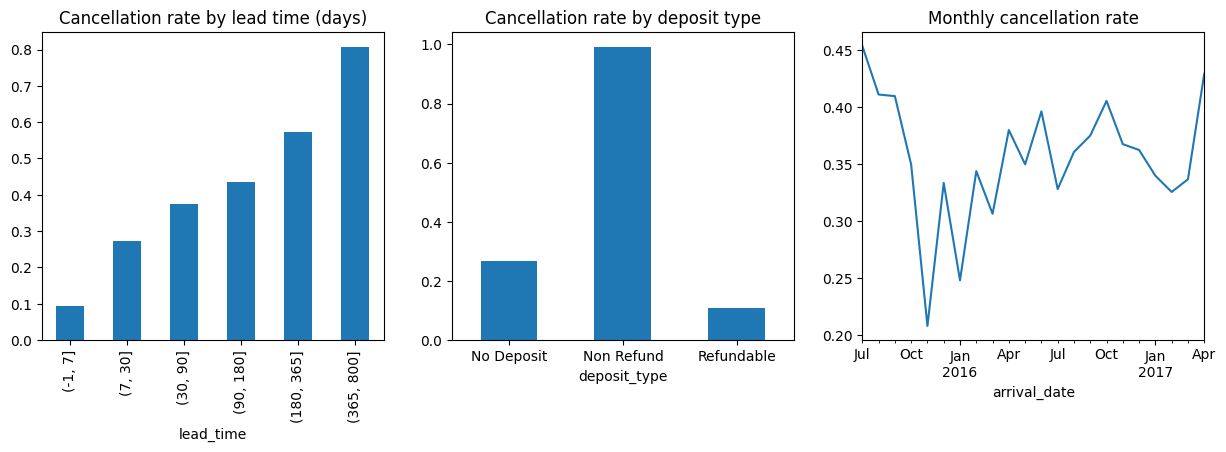

total_of_special_requests        -0.24
required_car_parking_spaces      -0.20
booking_changes                  -0.14
agent                            -0.10
is_repeated_guest                -0.08
previous_bookings_not_canceled   -0.06
company                          -0.04
babies                           -0.03
arrival_date_day_of_month        -0.01
arrival_date_year                -0.01
stays_in_weekend_nights          -0.01
children                         -0.00
stays_in_week_nights              0.02
arrival_date_week_number          0.02
adr                               0.03
adults                            0.06
days_in_waiting_list              0.06
previous_cancellations            0.13
lead_time                         0.32


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
lead = pd.cut(train_df["lead_time"], [-1, 7, 30, 90, 180, 365, 800])
train_df.groupby(lead, observed=True)["is_canceled"].mean().plot.bar(ax=ax[0], title="Cancellation rate by lead time (days)")
train_df.groupby("deposit_type")["is_canceled"].mean().plot.bar(ax=ax[1], rot=0, title="Cancellation rate by deposit type")
train_df.set_index("arrival_date")["is_canceled"].resample("ME").mean().plot(ax=ax[2], title="Monthly cancellation rate")
plt.show()
print(train_df.corr(numeric_only=True)["is_canceled"].drop("is_canceled").sort_values().round(2).to_string())

**Interpretation.** The plots and correlations describe associations within development data. Lead time, agency/deposit arrangements and special requests may reflect different booking processes and customer groups. They do not establish causes of cancellation or prove which features were available at an early decision point. Monthly differences motivate time-aware evaluation; they do not isolate a single cause of performance change.

## 4. Cleaning and features

### 4.1 Fixed rules
The code deduplicates within each partition, restricts ADR to 0–1000 and retains positive guest counts. It maps meal `Undefined` to `SC` and treats agent/company identifiers as categories. These operations do not learn thresholds from the test set, but their consequences and subjective choices still require qualification.

In [6]:
def clean(d):
    d = d.drop_duplicates()
    d = d[d["adr"].between(0, 1000) & (d[["adults", "children", "babies"]].sum(axis=1) > 0)].copy()
    d["meal"] = d["meal"].replace("Undefined", "SC")
    d[["agent", "company"]] = d[["agent", "company"]].astype("Int64").astype(str).replace("<NA>", np.nan)
    return d

train_df, test_df = clean(train_df), clean(test_df)
y_train, y_test = train_df["is_canceled"], test_df["is_canceled"]
print(f"Train: {train_df.shape}, cancel rate {y_train.mean():.3f} | Test: {test_df.shape}, cancel rate {y_test.mean():.3f}")

Train: (68354, 33), cancel rate 0.256 | Test: (18879, 33), cancel rate 0.345


### 4.2 Preprocessing and validation

Numeric features are imputed, optionally scaled, and combined with categorical imputation and one-hot encoding. The encoding is fitted inside each training fold. The feature function adds stay length, guest count, log lead time and agency/company-presence indicators.

Five expanding, row-based time-series folds supply development ROC-AUC. They preserve row order, but can split a calendar day. The same folds are reused during tuning and candidate ranking. Fold standard deviations are descriptive and are not confidence intervals.

In [7]:
def make_prep(scale=True, dense=False):
    num = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    cat = [("impute", SimpleImputer(strategy="constant", fill_value="none")),
           ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=not dense))]
    return ColumnTransformer([("num", Pipeline(num), make_column_selector(dtype_exclude=object)),
                              ("cat", Pipeline(cat), make_column_selector(dtype_include=object))])

def add_features(d):
    d = d.copy()
    d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
    d["total_guests"] = d["adults"] + d["children"].fillna(0) + d["babies"]
    d["log_lead_time"] = np.log1p(d["lead_time"])
    d["has_agent"] = d["agent"].notna().astype(int)
    d["has_company"] = d["company"].notna().astype(int)
    return d

tscv = TimeSeriesSplit(n_splits=5)

def cv_auc(model, X, cv=tscv):
    scores = cross_val_score(model, X, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return round(float(scores.mean()), 4), round(float(scores.std()), 4)

### 4.3 Checks for target-related information

The audit compares three feature sets: all eligible fields, removal of reservation status/date, and additional removal of fields with uncertain timing. Status can directly reveal the target. Assigned room, booking changes, waiting-list days, parking and country are also excluded from the final feature set.

A strong association alone does not establish when a feature was captured. The source paper describes a snapshot generally reconstructed for the day before arrival and fields drawn from several operational tables. These checks do not prove that every remaining feature was available at booking time or before cancellation.

In [8]:
parking = train_df[train_df["required_car_parking_spaces"] > 0]
print("Parking requests:", len(parking), "| cancelled:", parking["is_canceled"].sum())

drop = ["is_canceled", "arrival_date", "arrival_date_year"]
status = ["reservation_status", "reservation_status_date"]
later = ["assigned_room_type", "booking_changes", "days_in_waiting_list", "required_car_parking_spaces", "country"]
audit = Pipeline([("prep", make_prep(dense=True)), ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
for name, extra in [("all columns", []), ("no status columns", status), ("no leaking columns", status + later)]:
    print(f"CV ROC-AUC (mean, std), {name}:", cv_auc(audit, train_df.drop(columns=drop + extra)))

drop += status + later
X_train, X_test = train_df.drop(columns=drop), test_df.drop(columns=drop)

Parking requests: 6080 | cancelled: 0


CV ROC-AUC (mean, std), all columns: (1.0, 0.0)


CV ROC-AUC (mean, std), no status columns: (0.8282, 0.0464)


CV ROC-AUC (mean, std), no leaking columns: (0.7921, 0.0176)


**Reading this comparison.** The score change measures the effect of these particular feature exclusions under the chosen validation procedure. It is not a certificate that all remaining inputs are free of timing problems. Parking's association with the target does not prove that parking was recorded only on arrival, and the paper does not establish that country was confirmed only at check-in.

## 5. Preprocessing comparison

Four fixed variants compare imputation/encoding, scaling, engineered features and univariate selection. This is a development comparison using the same time-series folds; it is not an additional independent test.

In [9]:
def log_reg(*steps):
    return Pipeline(list(steps) + [("model", LogisticRegression(max_iter=1000))])

features = ("features", FunctionTransformer(add_features))
strategies = {
    "A: impute + one-hot": log_reg(("prep", make_prep(scale=False))),
    "B: A + scaling": log_reg(("prep", make_prep())),
    "C: B + engineered features": log_reg(features, ("prep", make_prep())),
    "D: C + SelectKBest(k=40)": log_reg(features, ("prep", make_prep()), ("select", SelectKBest(k=40))),
}
rows = [(name, *cv_auc(p, X_train), p.fit(X_train, y_train)[-1].n_iter_[0]) for name, p in strategies.items()]
pd.DataFrame(rows, columns=["Strategy", "CV ROC-AUC", "Std", "Solver iterations (max 1000)"])

,Strategy,CV ROC-AUC,Std,Solver iterations (max 1000)
0,A: impute + one-hot,0.7691,0.0159,1000
1,B: A + scaling,0.7667,0.0191,114
2,C: B + engineered features,0.7895,0.0107,156
3,D: C + SelectKBest(k=40),0.7859,0.0128,97


The scaled logistic variants converge more readily than the unscaled baseline. The table records the measured scores and iteration counts. Engineered features are retained for the subsequent comparison; univariate selection is not retained. Differences are development observations, not causal proof of a deployment benefit.

## 6. Candidate models

Logistic regression provides a regularised linear baseline. Random forest averages trees fitted to bootstrap samples. Histogram gradient boosting fits trees sequentially. Model definitions and seeds are retained from the submission. The data size and encoded feature space motivated this limited candidate set; the study is not an exhaustive algorithm benchmark.

In [10]:
models = {
    "Logistic": log_reg(features, ("prep", make_prep())),
    "Forest": Pipeline([features, ("prep", make_prep()), ("model", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
    "Boosting": Pipeline([features, ("prep", make_prep(dense=True)),
                                   ("model", HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE))]),
}
shuffled = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Boosting, shuffled folds:", cv_auc(models["Boosting"], X_train, cv=shuffled))
pd.DataFrame({name: cv_auc(m, X_train) for name, m in models.items()}, index=["CV ROC-AUC", "Std"]).T

Boosting, shuffled folds: (0.8398, 0.0024)


,CV ROC-AUC,Std
Logistic,0.7895,0.0107
Forest,0.7775,0.0166
Boosting,0.7913,0.0158


The shuffled-fold and time-series results use different training/validation partitions. A higher shuffled-fold score illustrates that evaluation design matters. Its difference from the chronological score does not isolate a precise amount of leakage or establish a causal explanation. The subsequent comparison uses the expanding time-series folds.

## 7. Tuning

Logistic regression tunes inverse regularisation `C`; forest tunes minimum leaf size; histogram boosting tunes learning rate and maximum leaf count. The finite grids are retained from the submitted analysis. Reusing development folds for tuning and ranking can make those development scores optimistic.

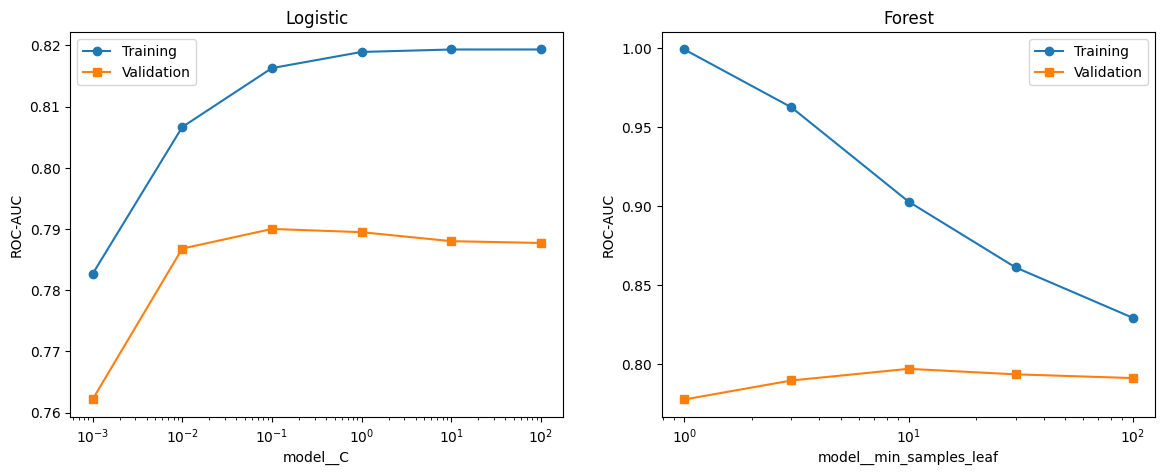

In [11]:
def tune_curve(ax, name, param, values):
    tr, va = validation_curve(models[name], X_train, y_train, param_name=param, param_range=values, cv=tscv, scoring="roc_auc", n_jobs=-1)
    ax.plot(values, tr.mean(axis=1), marker="o", label="Training")
    ax.plot(values, va.mean(axis=1), marker="s", label="Validation")
    ax.set(xscale="log", xlabel=param, ylabel="ROC-AUC", title=name)
    ax.legend()
    return values[va.mean(axis=1).argmax()]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
models["Logistic"].set_params(model__C=tune_curve(ax[0], "Logistic", "model__C", [0.001, 0.01, 0.1, 1, 10, 100]))
models["Forest"].set_params(model__min_samples_leaf=tune_curve(ax[1], "Forest", "model__min_samples_leaf", [1, 3, 10, 30, 100]))
plt.show()

The validation curves show how the chosen capacities perform under these folds. Training/validation differences describe fit behaviour on this dataset; they do not establish performance on new hotels or a future operating period. The settings selected by the original code are retained.

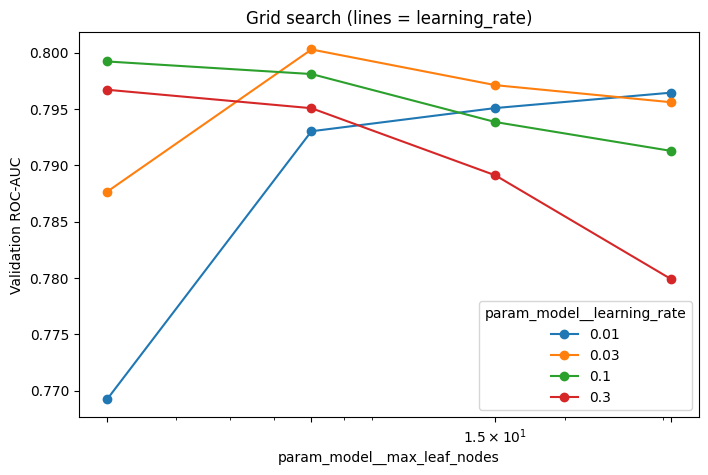

Best: {'model__learning_rate': 0.03, 'model__max_leaf_nodes': 7} 0.8003


In [12]:
grid = GridSearchCV(models["Boosting"],
                    {"model__learning_rate": [0.01, 0.03, 0.1, 0.3], "model__max_leaf_nodes": [3, 7, 15, 31]},
                    cv=tscv, scoring="roc_auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train)
models["Boosting"] = grid.best_estimator_
res = pd.DataFrame(grid.cv_results_)
res.pivot(index="param_model__max_leaf_nodes", columns="param_model__learning_rate", values="mean_test_score").plot(
    marker="o", logx=True, xticks=[3, 7, 15, 31], figsize=(8, 5), ylabel="Validation ROC-AUC", title="Grid search (lines = learning_rate)")
plt.show()
print("Best:", grid.best_params_, round(grid.best_score_, 4))

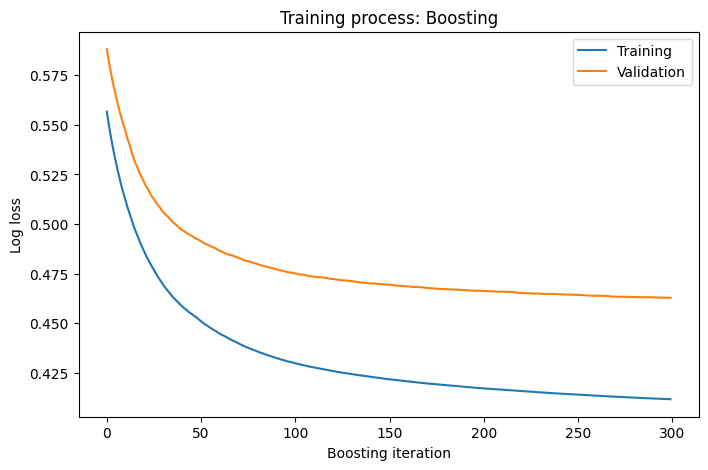

In [13]:
tr_idx, val_idx = list(tscv.split(X_train))[-1]
gb = clone(models["Boosting"]).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
curves = {}
for label, idx in [("Training", tr_idx), ("Validation", val_idx)]:
    X_part = gb[:-1].transform(X_train.iloc[idx])
    curves[label] = [log_loss(y_train.iloc[idx], p[:, 1]) for p in gb[-1].staged_predict_proba(X_part)]
pd.DataFrame(curves).plot(figsize=(8, 5), xlabel="Boosting iteration", ylabel="Log loss", title="Training process: Boosting")
plt.show()

The grid search uses development ROC-AUC. Boosting retains automatic early stopping: `max_iter=300` is an upper bound, not a statement that every fit runs 300 stages. The loss-curve fit used 300 stages, and the final full-development boosting fit used 300. Its internal split is not a forward-only validation procedure.

The grid chart's four horizontal marker positions are 3, 7, 15 and 31 leaves, from left to right.

### 7.1 Combining the tuned models

Soft voting averages probabilities from the three tuned models. The stacking comparator fits a logistic meta-model from internal out-of-fold predictions. Its `cv=3` uses ordinary stratified folds, not forward-only splits, so its internal training can include rows later than an inner validation row. It is retained as a documented exploratory comparator, not a temporally valid stacking design.

In [14]:
base = [(name, clone(m)) for name, m in models.items()]
models["Voting"] = VotingClassifier(base, voting="soft")
models["Stacking"] = StackingClassifier(base, final_estimator=LogisticRegression(max_iter=1000), cv=3)

## 8. Evaluation

The selection heuristic ranks development mean ROC-AUC, preferring logistic regression only if its mean lies within one standard deviation of the best candidate's mean. Otherwise it selects the highest mean. This is a stated heuristic, not a test of statistical equivalence or an independently registered protocol. The final partition is evaluated after this code selects the candidate.

In [15]:
tuned = pd.DataFrame({name: cv_auc(m, X_train) for name, m in models.items()}, index=["Mean", "Std"]).T
best = tuned["Mean"].idxmax()
tied = tuned.index[tuned["Mean"] >= tuned.loc[best, "Mean"] - tuned.loc[best, "Std"]]
final_name = "Logistic" if "Logistic" in tied else best
print(tuned, "\nWithin one std of best:", list(tied), "| Selected:", final_name)

            Mean     Std
Logistic  0.7900  0.0103
Forest    0.7969  0.0148
Boosting  0.8003  0.0106
Voting    0.8037  0.0113
Stacking  0.7401  0.0598 
Within one std of best: ['Forest', 'Boosting', 'Voting'] | Selected: Voting


The fixed rule selects **Voting** in this reproduction. Read the table with its fold variation and repeated use of development data in mind. Small ensemble margins do not demonstrate that additional operating complexity is worthwhile. The original split's five repeated patterns also limit independence of the final evaluation.

**Threshold selection.** The final development fold chooses a threshold under the assumed score `3 × false negatives + false positives`. The 3:1 ratio is an illustrative choice, not an observed hotel cost matrix. This fold also contributed to earlier tuning. Its selected threshold is then applied to the final partition without changing the selection rule from final-period results.

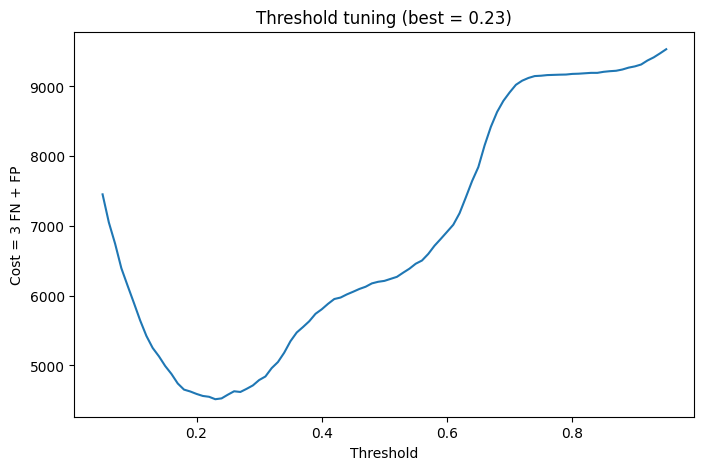

In [16]:
def cost_of(y, proba, t):
    tn, fp, fn, tp = confusion_matrix(y, proba >= t).ravel()
    return 3 * fn + fp

val_proba = clone(models[final_name]).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx]).predict_proba(X_train.iloc[val_idx])[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
costs = pd.Series([cost_of(y_train.iloc[val_idx], val_proba, t) for t in thresholds], thresholds)
threshold = costs.idxmin()
costs.plot(figsize=(8, 5), xlabel="Threshold", ylabel="Cost = 3 FN + FP", title=f"Threshold tuning (best = {threshold:.2f})")
plt.show()

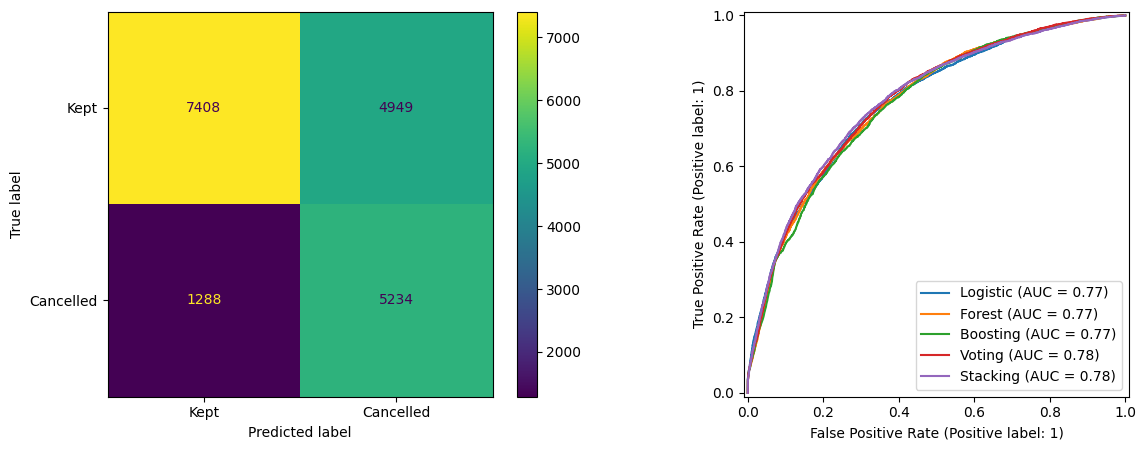

              precision    recall  f1-score   support

        Kept      0.852     0.599     0.704     12357
   Cancelled      0.514     0.803     0.627      6522

    accuracy                          0.670     18879
   macro avg      0.683     0.701     0.665     18879
weighted avg      0.735     0.670     0.677     18879

Threshold 0.23 | cost 8813 vs 13470 at 0.50


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m.fit(X_train, y_train), X_test, y_test, name=name, ax=ax[1])

test_proba = models[final_name].predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Kept", "Cancelled"], ax=ax[0])
plt.show()
print(classification_report(y_test, test_pred, target_names=["Kept", "Cancelled"], digits=3))
print(f"Threshold {threshold:.2f} | cost {cost_of(y_test, test_proba, threshold)} vs {cost_of(y_test, test_proba, 0.5)} at 0.50")

In [18]:
errors = test_df.assign(predicted=test_proba)
print(errors.groupby(errors["arrival_date"].dt.to_period("M"))[["is_canceled", "predicted"]].mean().round(3))
print(errors.groupby("hotel").apply(lambda g: roc_auc_score(g["is_canceled"], g["predicted"])).round(3))

              is_canceled  predicted
arrival_date                        
2017-04             0.322      0.305
2017-05             0.329      0.281
2017-06             0.340      0.297
2017-07             0.352      0.316
2017-08             0.367      0.306
hotel
City Hotel      0.757
Resort Hotel    0.815
dtype: float64


**Retrospective results.** The selected Voting model reaches ROC-AUC **0.7757** on 18,879 cleaned test rows. At threshold **0.23**, cancellation precision is **0.514**, recall **0.803**, F1 **0.627** and accuracy **0.670**.

The assumed cost score is 8,813, compared with 13,470 at threshold 0.50: a 34.57% reduction in this score. This is not measured revenue or operational savings. Monthly and hotel breakdowns describe the held-out-by-row-order portion of this historical dataset; they do not establish current calibration or explain the causes of the differences.

## 9. Model interpretation

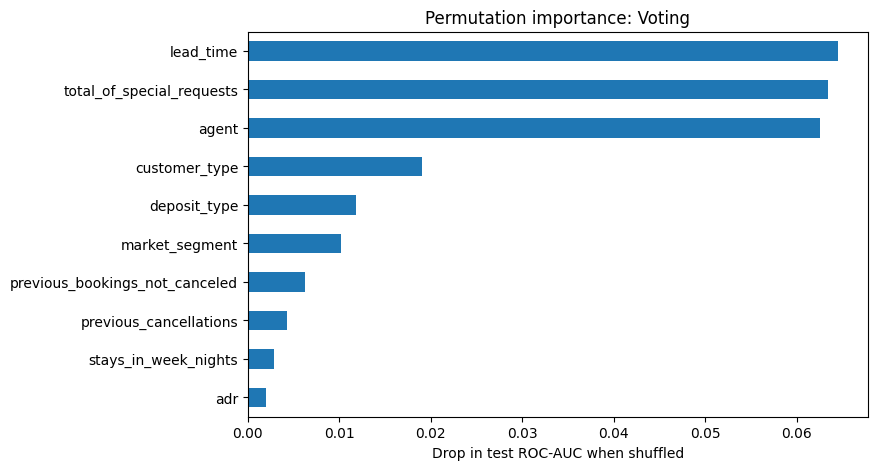

In [19]:
imp = permutation_importance(models[final_name], X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, X_test.columns).nlargest(10).sort_values().plot.barh(
    figsize=(8, 5), xlabel="Drop in test ROC-AUC when shuffled", title=f"Permutation importance: {final_name}")
plt.show()

Permutation importance measures how the fitted model's test ROC-AUC changes when one input column is shuffled. Correlated features and the shuffle distribution affect the ranking. It is a model-dependence diagnostic, not a causal analysis. Agency IDs are anonymised; proposed actions would require the hotel's own mapping, a justified decision time and an independently evaluated policy.

## 10. Conclusion

This academic experiment demonstrates data audits, preprocessing pipelines, model comparison, bounded tuning, ensemble comparison, threshold selection and error analysis. Its reproduced selected-model ROC-AUC is 0.7757; the additional ensemble complexity and assumed cost benefit remain limited claims.

The original arrival-ordered split has a shared boundary date and five exact row patterns in both partitions. Feature availability at a proposed early decision time is not established. Inner stacking folds are not forward-only; development folds are reused; the dataset covers two hotels in an old period; calibration and real costs are unverified. The final outcomes have now been inspected, so future changes require a new evaluation plan and genuinely reserved data.

The next research step would be an as-of-time feature table and frozen date/group-aware partitions, followed by evaluation on a separate operating period. Any booking intervention or overbooking policy would require operational testing. No deployment or business benefit is claimed.

## 11. References
- Antonio, N., de Almeida, A. and Nunes, L. (2019) 'Hotel booking demand datasets', *Data in Brief*, 22, pp. 41-49.
- Burkov, A. (2019) *The Hundred-Page Machine Learning Book*. Quebec City: Andriy Burkov.
- Burkov, A. (2020) *Machine Learning Engineering*. Montreal: True Positive Inc.
- Duong-Trung, N. (2026) *teaching* [GitHub]. Available at: https://github.com/duongtrung/teaching (Accessed: 17 September 2026).
- Kaufman, S. et al. (2012) 'Leakage in data mining', *ACM TKDD*, 6(4), pp. 1-21.
- Mostipak, J. (2020) *Hotel booking demand* [Dataset]. Kaggle.
- Pedregosa, F. et al. (2011) 'Scikit-learn', *JMLR*, 12, pp. 2825-2830, with the User Guide at https://scikit-learn.org/stable/user_guide.html.